# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Сакиев Сармат Арсенович
**Дата:** 11.10.2026  
**Использованные источники и инструменты:** Srape This Site (https://www.scrapethissite.com/pages/forms/), Python, Jupyter Notebook, Requests, Beautiful Soup (bs4), Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.

In [1]:
pip install pandas numpy matplotlib seaborn requests beautifulsoup4 scikit-learn lxml

In [2]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
from pathlib import Path
from datetime import datetime

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

<a id="result-1-2"></a>
**Результаты 1.1**

In [3]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
from pathlib import Path
from datetime import datetime

url = "https://www.scrapethissite.com/pages/forms/"

response = requests.get(url, timeout=30)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

print("Название страницы:", soup.title.get_text(strip=True))
print("Строк команд:", len(soup.select("tr.team")))
print("Ссылки на страницы:")
print([
    link.get("href")
    for link in soup.select(".pagination a")
])

Название страницы: Hockey Teams: Forms, Searching and Pagination | Scrape This Site | A public sandbox for learning web scraping
Строк команд: 25
Ссылки на страницы:
['/pages/forms/?page_num=1', '/pages/forms/?page_num=2', '/pages/forms/?page_num=3', '/pages/forms/?page_num=4', '/pages/forms/?page_num=5', '/pages/forms/?page_num=6', '/pages/forms/?page_num=7', '/pages/forms/?page_num=8', '/pages/forms/?page_num=9', '/pages/forms/?page_num=10', '/pages/forms/?page_num=11', '/pages/forms/?page_num=12', '/pages/forms/?page_num=13', '/pages/forms/?page_num=14', '/pages/forms/?page_num=15', '/pages/forms/?page_num=16', '/pages/forms/?page_num=17', '/pages/forms/?page_num=18', '/pages/forms/?page_num=19', '/pages/forms/?page_num=20', '/pages/forms/?page_num=21', '/pages/forms/?page_num=22', '/pages/forms/?page_num=23', '/pages/forms/?page_num=24', '/pages/forms/?page_num=1']


<a id="result-1-2"></a>
**Результаты 1.2**

In [4]:
last_page_url = url + "?page_num=24"

response_last = requests.get(last_page_url, timeout=30)
response_last.raise_for_status()

soup_last = BeautifulSoup(response_last.text, "html.parser")

print("Строк команд на странице 24:", len(soup_last.select("tr.team")))
print("Первая команда:", soup_last.select_one("tr.team").get_text(" ", strip=True))

Строк команд на странице 24: 7
Первая команда: San Jose Sharks 2011 43 29 10 0.524 228 210 18


<a id="result-1-3"></a>
**Результаты 1.3**

In [5]:
all_rows = []
pages_processed = 0

for page_num in range(1, 25):
    page_url = url + f"?page_num={page_num}"

    response = requests.get(page_url, timeout=30)
    response.raise_for_status()

    page_soup = BeautifulSoup(response.text, "html.parser")
    rows = page_soup.select("tr.team")

    if not rows:
        print(f"Страница {page_num} не содержит команд.")
        continue

    for row in rows:
        cells = row.select("td")

        all_rows.append([
            cell.get_text(" ", strip=True)
            for cell in cells
        ])

    pages_processed += 1

print("Обработано страниц:", pages_processed)
print("Собрано строк:", len(all_rows))
print("Число столбцов:", len(all_rows[0]) if all_rows else 0)

Обработано страниц: 24
Собрано строк: 582
Число столбцов: 9


<a id="result-1-4"></a>
**Результаты 1.4**

In [6]:
columns = [
    "team", "year", "wins", "losses", "ot_losses",
    "win_rate", "goals_for", "goals_against", "goal_diff"
]

df = pd.DataFrame(all_rows, columns=columns)

display(df.head())
print(df.dtypes)
print("Размер таблицы:", df.shape)

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25


team             object
year             object
wins             object
losses           object
ot_losses        object
win_rate         object
goals_for        object
goals_against    object
goal_diff        object
dtype: object
Размер таблицы: (582, 9)


<a id="result-1-5"></a>
**Результаты 1.5**

In [7]:
numeric_columns = [
    "year", "wins", "losses", "ot_losses", "win_rate",
    "goals_for", "goals_against", "goal_diff"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["year"] = df["year"].astype("Int64")

data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

csv_path = data_dir / "hockey_raw.csv"
df.to_csv(csv_path, index=False)

print("Размер таблицы:", df.shape)
print("\nТипы данных:")
print(df.dtypes)
print("\nКоличество пропусков:")
print(df.isna().sum())
print("\nCSV сохранён:", csv_path)


Размер таблицы: (582, 9)

Типы данных:
team              object
year               Int64
wins               int64
losses             int64
ot_losses        float64
win_rate         float64
goals_for          int64
goals_against      int64
goal_diff          int64
dtype: object

Количество пропусков:
team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64

CSV сохранён: data/hockey_raw.csv


In [8]:
df_check = pd.read_csv(csv_path)

print("Размер загруженной таблицы:", df_check.shape)
display(df_check.head())

print("Совпадает ли число строк:", len(df_check) == len(df))
print("Совпадают ли названия столбцов:",
      list(df_check.columns) == list(df.columns))

Размер загруженной таблицы: (582, 9)


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


Совпадает ли число строк: True
Совпадают ли названия столбцов: True


В качестве источника данных использован сайт [Scrape This Site — Hockey Teams](https://www.scrapethissite.com/pages/forms/), содержащий статистику хоккейных команд по сезонам.

С помощью библиотек `requests` и `BeautifulSoup` загружены и обработаны 24 страницы сайта. Получено 582 записи с девятью требуемыми столбцами. Числовые поля преобразованы в соответствующие типы данных с использованием библиотеки `pandas`.

Подготовленная таблица сохранена в файл `data/hockey_raw.csv`. Корректность сбора и сохранения данных проверялась путём повторного чтения CSV-файла и сравнения структуры полученной таблицы с исходной.

Результаты сбора данных и проверки сохранения представлены в [разделе 1.1](#result-1-1).

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [9]:
print("Типы данных:")
display(df.dtypes)

print("\nКоличество пропусков:")
display(df.isna().sum())

print("\nПолных дубликатов:", df.duplicated().sum())
print(
    "Повторяющихся пар команда-год:",
    df.duplicated(subset=["team", "year"]).sum()
)

check_goal_diff = (
    df["goal_diff"] == df["goals_for"] - df["goals_against"]
).all()

check_nonnegative = (
    (df[["wins", "losses", "goals_for", "goals_against"]] >= 0)
    .all()
    .all()
    and df["ot_losses"].dropna().ge(0).all()
)

check_win_rate = df["win_rate"].between(0, 1).all()

print("\nПроверки согласованности:")
print("Разница голов рассчитана верно:", check_goal_diff)
print("Статистические показатели неотрицательны:", check_nonnegative)
print("win_rate находится в диапазоне от 0 до 1:", check_win_rate)

print("\nОписательная статистика:")
display(df.describe())

Типы данных:


,0
team,object
year,Int64
wins,int64
losses,int64
ot_losses,float64
win_rate,float64
goals_for,int64
goals_against,int64
goal_diff,int64



Количество пропусков:


,0
team,0
year,0
wins,0
losses,0
ot_losses,224
win_rate,0
goals_for,0
goals_against,0
goal_diff,0



Полных дубликатов: 0
Повторяющихся пар команда-год: 0

Проверки согласованности:
Разница голов рассчитана верно: True
Статистические показатели неотрицательны: True
win_rate находится в диапазоне от 0 до 1: True

Описательная статистика:


,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
count,582.0,582.000000,582.000000,358.000000,582.000000,582.000000,582.000000,582.000000
mean,2000.907216,36.943299,32.353952,7.460894,0.458519,234.063574,234.063574,0.000000
std,6.330674,8.926081,8.411439,3.610191,0.102237,40.548915,42.510718,45.277458
min,1990.0,9.000000,11.000000,0.000000,0.119000,115.000000,115.000000,-196.000000
25%,1996.0,31.000000,27.000000,5.000000,0.390000,211.000000,207.000000,-27.000000
50%,2001.0,38.000000,31.000000,7.000000,0.463000,231.000000,232.500000,4.000000
75%,2007.0,43.000000,37.000000,10.000000,0.534000,254.000000,258.750000,31.000000
max,2011.0,62.000000,71.000000,18.000000,0.756000,369.000000,414.000000,144.000000


Проверка качества показала, что таблица содержит 582 записи и 9 столбцов. Полных дубликатов и повторяющихся пар `team`–`year` не обнаружено.

В столбце `ot_losses` отсутствуют 224 значения. Эти пропуски сохранены, поскольку отсутствие сведений нельзя считать нулевым значением.

Проверка согласованности подтвердила, что во всех строках выполняется равенство `goal_diff = goals_for - goals_against`. Дополнительно проверены неотрицательность основных статистических показателей и принадлежность `win_rate` диапазону от 0 до 1.

Проверка формулы `wins / (wins + losses)` выявила расхождения. Например, для Boston Bruins в 1990 году указаны 44 победы, 24 поражения и `win_rate = 0,550`. Это соответствует приблизительно 80 сыгранным матчам, тогда как сумма побед и поражений равна 68. Следовательно, исходный показатель нельзя во всех сезонах восстановить по этой простой формуле, поэтому `win_rate` сохранён без изменений.

Результаты проверок и описательная статистика представлены в [разделе 1.2](#result-1-2).

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

<a id="result-2-1"></a>
**Результаты 2.1**

In [10]:
import numpy as np

median_by_year = df.groupby("year")["win_rate"].median()

current = df.copy()
current["target_year"] = current["year"] + 1

future = df[["team", "year", "win_rate"]].rename(
    columns={
        "year": "target_year",
        "win_rate": "future_win_rate"
    }
)

merged = current.merge(
    future,
    on=["team", "target_year"],
    how="left",
    indicator=True
)

excluded = merged[merged["_merge"] == "left_only"].copy()
paired = merged[merged["_merge"] == "both"].copy()

paired["future_median"] = paired["target_year"].map(median_by_year)

paired["target"] = (
    paired["future_win_rate"] > paired["future_median"]
).astype(int)

median_equal = (
    paired["future_win_rate"] == paired["future_median"]
)

print("Всего исходных строк:", len(df))
print("Получено пар:", len(paired))
print("Исключено строк без следующего сезона:", len(excluded))
print("Годы исключённых строк:", sorted(excluded["year"].unique().tolist()))
print("Число случаев равенства будущей медиане:", int(median_equal.sum()))

print("\nРаспределение target:")
display(paired["target"].value_counts().sort_index())

print("\nПримеры с target = 1 и target = 0:")
example_1 = paired[paired["target"] == 1].head(1)
example_0 = paired[paired["target"] == 0].head(1)

examples = pd.concat([example_1, example_0])

display(
    examples[
        [
            "team", "year", "target_year", "win_rate",
            "future_win_rate", "future_median", "target"
        ]
    ]
)

print("\nПроверка вручную:")
for _, row in examples.iterrows():
    print(
        f'{row["team"]}: {int(row["year"])} -> {int(row["target_year"])}, '
        f'будущий win_rate = {row["future_win_rate"]:.3f}, '
        f'медиана = {row["future_median"]:.3f}, '
        f'target = {row["target"]}'
    )


Всего исходных строк: 582
Получено пар: 516
Исключено строк без следующего сезона: 66
Годы исключённых строк: [1992, 1994, 1995, 1996, 2003, 2005, 2010, 2011]
Число случаев равенства будущей медиане: 23

Распределение target:


,count
target,
0,266
1,250



Примеры с target = 1 и target = 0:


,team,year,target_year,win_rate,future_win_rate,future_median,target
0,Boston Bruins,1990,1991,0.550,0.450,0.444,1
1,Buffalo Sabres,1990,1991,0.388,0.388,0.444,0



Проверка вручную:
Boston Bruins: 1990 -> 1991, будущий win_rate = 0.450, медиана = 0.444, target = 1
Buffalo Sabres: 1990 -> 1991, будущий win_rate = 0.388, медиана = 0.444, target = 0


Каждая запись команды за сезон \(t\) объединена с записью той же команды за сезон \(t+1\). Медиана `win_rate` рассчитана отдельно для каждого будущего сезона по всей исходной таблице.

Целевая переменная `target` принимает значение 1, если `future_win_rate` строго выше медианы соответствующего сезона, и 0 в противном случае.

Из 582 исходных записей сформировано 516 пар. Исключено 66 строк, для которых не найдена запись той же команды ровно за следующий год. Годы исключённых исходных сезонов: 1992, 1994, 1995, 1996, 2003, 2005, 2010 и 2011. В 23 случаях `future_win_rate` равен медиане; эти наблюдения отнесены к классу 0.

В итоговой выборке 266 записей класса 0 и 250 записей класса 1.

Расчёт проверен вручную на двух примерах: для Boston Bruins в паре сезонов 1990–1991 `future_win_rate = 0,450` при медиане 0,444, поэтому `target = 1`. Для Buffalo Sabres значение равно 0,388, поэтому `target = 0`.

Число пар, исключённые строки, распределение классов и примеры приведены в [результатах раздела 2.1](#result-2-1).

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

<a id="result-2-2"></a>
**Результаты 2.2**

In [11]:
train = paired[paired["target_year"] <= 2005].copy()

validation = paired[
    paired["target_year"].between(2006, 2008)
].copy()

test = paired[
    paired["target_year"].between(2009, 2011)
].copy()

for name, part in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}")
    print("Размер:", len(part))
    print("Годы target_year:", sorted(part["target_year"].unique().tolist()))
    print("Доля класса 1:", round(part["target"].mean(), 4))
    print("Количество класса 0:", int((part["target"] == 0).sum()))
    print("Количество класса 1:", int((part["target"] == 1).sum()))



Train
Размер: 338
Годы target_year: [1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003]
Доля класса 1: 0.4911
Количество класса 0: 172
Количество класса 1: 166

Validation
Размер: 89
Годы target_year: [2006, 2007, 2008]
Доля класса 1: 0.4719
Количество класса 0: 47
Количество класса 1: 42

Test
Размер: 89
Годы target_year: [2009, 2010, 2011]
Доля класса 1: 0.4719
Количество класса 0: 47
Количество класса 1: 42


Для оценки модели выполнено временное разделение по году прогнозируемого сезона `target_year`.

Обучающая выборка содержит 338 пар с `target_year <= 2005`: 172 записи класса 0 и 166 записей класса 1. Доля класса 1 равна 0,4911. Фактически представлены годы с 1991 по 2003.

Валидационная выборка содержит 89 пар за 2006–2008 годы: 47 записей класса 0 и 42 записи класса 1. Доля класса 1 составляет 0,4719.

Тестовая выборка содержит 89 пар за 2009–2011 годы: 47 записей класса 0 и 42 записи класса 1. Доля класса 1 также равна 0,4719.

Столбцы `future_win_rate` и `future_median` недоступны на момент прогноза, поскольку содержат сведения о будущем сезоне. Столбец `target` является целевой переменной, а не признаком модели. `target_year` используется для разделения данных и также не включается в признаки.

Случайное перемешивание могло бы привести к попаданию более поздних сезонов в обучение, а более ранних — в тестирование. Временное разделение имитирует реальную ситуацию, когда модель обучается на прошлом и применяется к будущим сезонам.

Размеры выборок, фактические годы и доли классов представлены в [результатах раздела 2.2](#result-2-2).

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

**Ответ 3.1:**

**Исследовательский вопрос 1. Связан ли процент побед команды в текущем сезоне (`win_rate`) с её успешностью в следующем сезоне?**

Предполагается, что команды с более высоким текущим процентом побед чаще будут относиться к классу `target = 1`. Проверка этого предположения позволит оценить полезность `win_rate` как признака модели и сравнить его прогностическую способность с простым базовым ориентиром. При этом связь может быть неполной: результаты команды способны изменяться от сезона к сезону, а целевая переменная определяется относительно медианы конкретного сезона.

**Исследовательский вопрос 2. Связаны ли разница голов (`goal_diff`), количество забитых голов (`goals_for`) и количество пропущенных голов (`goals_against`) с будущей успешностью команды?**

Предполагается, что положительная разница голов, большее количество забитых голов и меньшее количество пропущенных голов связаны с более высокой вероятностью получить `target = 1` в следующем сезоне. Результаты помогут определить, какие показатели стоит включить в модель. Однако эти признаки частично дублируют информацию, поскольку `goal_diff` вычисляется как разность `goals_for` и `goals_against`. Кроме того, выявленная связь не доказывает причинно-следственную зависимость.

Для проверки вопросов использованы числовые сводки, графики и примеры конкретных команд. Результаты анализа представлены в [разделе 3.1](#result-3-1).

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

<a id="result3-1"></a>
**Результаты 3.1**

Числовые характеристики по классам target:


win_rate        goal_diff        goals_for        goals_against       
           mean median      mean median      mean median          mean median
target                                                                       
0         0.415  0.415    -20.18  -14.0   226.955  225.0       247.135  247.0
1         0.503  0.512     21.62   25.0   245.504  243.5       223.884  221.0

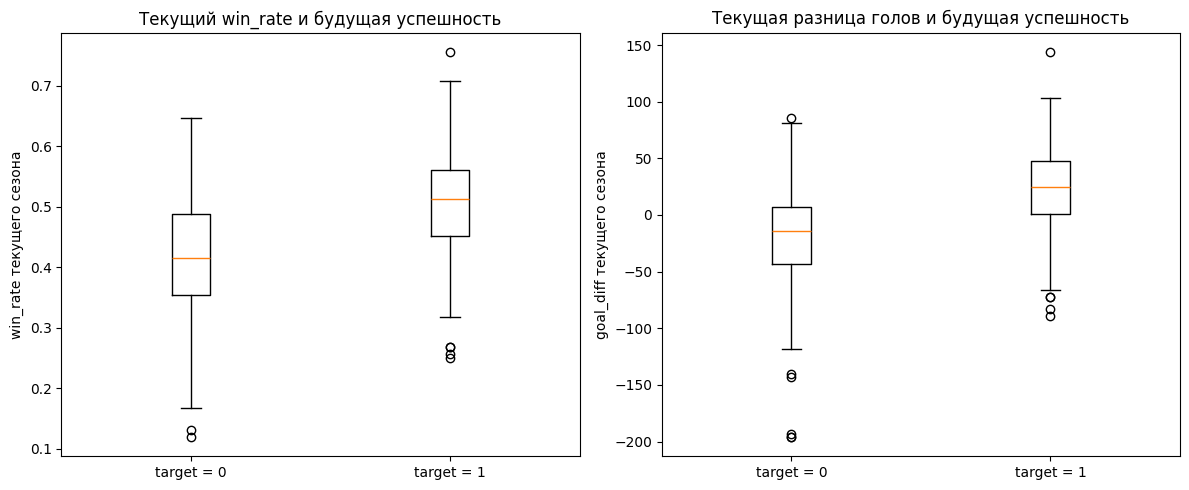

Пример команды с высоким текущим win_rate, но target = 0:


,team,year,target_year,win_rate,future_win_rate,future_median,target
405,Buffalo Sabres,2006,2007,0.646,0.476,0.506,0


Пример команды с низким текущим win_rate, но target = 1:


,team,year,target_year,win_rate,future_win_rate,future_median,target
36,Quebec Nordiques,1991,1992,0.25,0.56,0.476,1


In [12]:

import matplotlib.pyplot as plt

features_eda = [
    "win_rate", "goal_diff", "goals_for", "goals_against"
]

print("Числовые характеристики по классам target:")
display(
    paired.groupby("target")[features_eda]
    .agg(["mean", "median"])
    .round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    [
        paired.loc[paired["target"] == 0, "win_rate"],
        paired.loc[paired["target"] == 1, "win_rate"]
    ],
    tick_labels=["target = 0", "target = 1"]
)
axes[0].set_title("Текущий win_rate и будущая успешность")
axes[0].set_ylabel("win_rate текущего сезона")

axes[1].boxplot(
    [
        paired.loc[paired["target"] == 0, "goal_diff"],
        paired.loc[paired["target"] == 1, "goal_diff"]
    ],
    tick_labels=["target = 0", "target = 1"]
)
axes[1].set_title("Текущая разница голов и будущая успешность")
axes[1].set_ylabel("goal_diff текущего сезона")

plt.tight_layout()
plt.show()

example_target_0 = paired.loc[paired["target"] == 0].nlargest(
    1, "win_rate"
)
example_target_1 = paired.loc[paired["target"] == 1].nsmallest(
    1, "win_rate"
)

print("Пример команды с высоким текущим win_rate, но target = 0:")
display(
    example_target_0[
        ["team", "year", "target_year", "win_rate",
         "future_win_rate", "future_median", "target"]
    ]
)

print("Пример команды с низким текущим win_rate, но target = 1:")
display(
    example_target_1[
        ["team", "year", "target_year", "win_rate",
         "future_win_rate", "future_median", "target"]
    ]
)


**Ответ 3.2:**

### 3.2. Результаты исследовательского анализа

**1. Связь текущего процента побед с будущей успешностью.**

Средний `win_rate` в группе `target = 1` составляет 0,503, а медианный — 0,512. Для группы `target = 0` соответствующие значения равны 0,415 и 0,415. Таким образом, команды, которые в следующем сезоне оказались выше медианы лиги по проценту побед, в среднем уже показывали более высокие результаты в текущем сезоне.

При этом связь не является однозначной. Например, у Buffalo Sabres в сезоне 2006 года `win_rate` составлял 0,646, однако команда получила `target = 0`: в сезоне 2007 года её показатель снизился до 0,476 при медиане 0,506. Это подтверждает, что высокий результат текущего сезона не гарантирует сохранения относительной успешности.

**Ограничение интерпретации:** сравнение групп показывает статистическую связь, но не доказывает, что высокий процент побед сам по себе вызывает успех в следующем сезоне. Кроме того, целевая переменная определяется относительно медианы каждого сезона.

**2. Связь разницы голов и количества забитых и пропущенных голов с будущей успешностью.**

Средняя разница голов у команд с `target = 1` составляет 21,62, тогда как у команд с `target = 0` она равна −20,18. Среднее количество забитых голов составляет соответственно 245,504 и 226,955, а пропущенных — 223,884 и 247,135.

Эти результаты согласуются с предположением, что более высокая результативность и меньшее количество пропущенных голов связаны с большей вероятностью оказаться выше медианы процента побед в следующем сезоне.

Примером изменения результатов служит Quebec Nordiques в сезоне 1991 года: текущий `win_rate` команды составлял 0,250, но в следующем сезоне вырос до 0,560 при медиане 0,476. Поэтому команда получила `target = 1`, несмотря на низкий показатель в исходном сезоне.

**Ограничение интерпретации:** `goal_diff` рассчитывается как разность `goals_for` и `goals_against`, поэтому эти признаки частично дублируют информацию. По описательной статистике нельзя установить, какой из них вносит наибольший самостоятельный вклад в прогноз.

**Общий вывод.**

Числовые сводки указывают на различия между группами по текущему проценту побед, разнице голов, количеству забитых и пропущенных голов. Эти признаки представляются полезными кандидатами для построения модели. Однако отдельные примеры показывают, что команды могут существенно улучшать или ухудшать результаты. Поэтому прогноз следует оценивать на более поздних сезонах, не использовавшихся при обучении, а обнаруженные закономерности рассматривать как статистические связи, а не причинно-следственные зависимости.

Результаты числового анализа, графики и примеры команд приведены в [результатах раздела 3.1](#result-3-1).

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

<a id="result4-1"></a>
**Результаты 4.1**

In [13]:
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

y_train = train["target"]
y_val = validation["target"]

constant_probability = y_train.mean()

baseline_constant = np.full(
    len(validation),
    constant_probability
)

baseline_win_rate = validation["win_rate"]

auc_constant = roc_auc_score(y_val, baseline_constant)
auc_win_rate = roc_auc_score(y_val, baseline_win_rate)

baseline_results = pd.DataFrame({
    "Модель": [
        "Константный baseline",
        "Текущий win_rate"
    ],
    "Validation ROC-AUC": [
        auc_constant,
        auc_win_rate
    ]
})

print("Доля класса 1 в train:", round(constant_probability, 4))
display(baseline_results)

Доля класса 1 в train: 0.4911


,Модель,Validation ROC-AUC
0,Константный baseline,0.500000
1,Текущий win_rate,0.756839


**Ответ 4.1:**

В качестве первого базового ориентира использован константный прогноз, основанный на доле класса 1 в обучающей выборке. Эта доля составила 0,4911. На валидационной выборке константный baseline показал ROC-AUC = 0,500.

Вторым ориентиром выступил текущий процент побед команды (`win_rate`), использованный для ранжирования команд по ожидаемой успешности в следующем сезоне. Его ROC-AUC на валидационной выборке составил 0,7568.

Таким образом, текущий `win_rate` заметно превосходит константный прогноз и позволяет достаточно хорошо различать команды, которые в следующем сезоне окажутся выше и не выше медианы лиги. Значение ROC-AUC = 0,500 у константного baseline соответствует отсутствию способности ранжировать наблюдения по целевому классу. Поэтому обучаемая модель должна сравниваться с обоими ориентирами, а для демонстрации практической пользы обучения желательно превзойти ROC-AUC = 0,7568 на validation.

Результаты базовых ориентиров приведены в [ячейке с результатами раздела 4.1](#result-4-1).

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

<a id="result4-2"></a>
**Результаты 4.2**

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

feature_columns = [
    "win_rate",
    "wins",
    "losses",
    "ot_losses",
    "goals_for",
    "goals_against",
    "goal_diff"
]

X_train = train[feature_columns]
y_train = train["target"]

X_val = validation[feature_columns]
y_val = validation["target"]

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_train, y_train)

val_probabilities = logistic_model.predict_proba(X_val)[:, 1]
auc_logistic = roc_auc_score(y_val, val_probabilities)

comparison_42 = pd.DataFrame({
    "Модель": [
        "Константный baseline",
        "Текущий win_rate",
        "Логистическая регрессия"
    ],
    "Validation ROC-AUC": [
        auc_constant,
        auc_win_rate,
        auc_logistic
    ]
})

display(comparison_42)
print("ROC-AUC логистической регрессии:", round(auc_logistic, 6))

,Модель,Validation ROC-AUC
0,Константный baseline,0.500000
1,Текущий win_rate,0.756839
2,Логистическая регрессия,0.757345


ROC-AUC логистической регрессии: 0.757345


**Ответ 4.2:**

В качестве первой модели использована логистическая регрессия. В качестве признаков выбраны `win_rate`, `wins`, `losses`, `ot_losses`, `goals_for`, `goals_against` и `goal_diff`. Они характеризуют результаты команды в текущем сезоне и потенциально могут быть связаны с её успешностью в следующем сезоне.

Для обработки данных применён `Pipeline`, включающий заполнение пропусков медианными значениями, стандартизацию признаков и логистическую регрессию. Параметры обработки обучались только на обучающей выборке, что позволяет избежать утечки информации из validation.

ROC-AUC логистической регрессии на валидационной выборке составил 0,7573. Это немного выше результата базового ориентира `win_rate` (0,7568) и заметно выше константного baseline (0,5000).

Таким образом, логистическая регрессия демонстрирует способность ранжировать команды по будущей успешности, однако её преимущество перед использованием одного `win_rate` практически отсутствует: разница ROC-AUC составляет около 0,0005. Это может означать, что выбранные дополнительные признаки дают мало новой информации сверх текущего процента побед. Для проверки этого предположения в следующем пункте будет проведён контролируемый эксперимент на validation.

Результаты сравнения представлены в [ячейке с результатами раздела 4.2](#result-4-2).

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

**Гипотеза эксперимента.** Предполагается, что логистическая регрессия, использующая только `win_rate`, покажет ROC-AUC, близкий к модели со всеми семью признаками. Это связано с тем, что текущий процент побед уже отражает общую успешность команды, а дополнительные показатели могут содержать частично дублирующую информацию. Если модель с одним признаком покажет сопоставимый результат, предпочтение можно отдать более простой модели.

<a id="result4-3"></a>
**Результаты 4.3**

In [15]:
single_feature_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

single_feature_model.fit(
    train[["win_rate"]],
    train["target"]
)

single_feature_probabilities = single_feature_model.predict_proba(
    validation[["win_rate"]]
)[:, 1]

auc_single_feature = roc_auc_score(
    validation["target"],
    single_feature_probabilities
)

experiment_results = pd.DataFrame({
    "Модель": [
        "Логистическая регрессия: 7 признаков",
        "Логистическая регрессия: только win_rate"
    ],
    "Validation ROC-AUC": [
        auc_logistic,
        auc_single_feature
    ]
})

display(experiment_results)

if auc_single_feature > auc_logistic:
    print("Выбор по validation: модель только с win_rate")
elif auc_logistic > auc_single_feature:
    print("Выбор по validation: модель с 7 признаками")
else:
    print("Модели показали одинаковый ROC-AUC")

,Модель,Validation ROC-AUC
0,Логистическая регрессия: 7 признаков,0.757345
1,Логистическая регрессия: только win_rate,0.756839


Выбор по validation: модель с 7 признаками


**Ответ 4.3:**

В качестве эксперимента было изменено количество признаков логистической регрессии. Сравнивались модель с семью признаками (`win_rate`, `wins`, `losses`, `ot_losses`, `goals_for`, `goals_against`, `goal_diff`) и модель, использующая только `win_rate`. До проведения эксперимента предполагалось, что результаты будут близкими, поскольку процент побед уже отражает общую успешность команды.

На валидационной выборке модель с семью признаками показала ROC-AUC = 0,757345, а модель только с `win_rate` — ROC-AUC = 0,756839. Таким образом, модель с семью признаками показала немного лучший результат. Разница составила приблизительно 0,0005.

По результатам validation для дальнейшей оценки выбрана логистическая регрессия с семью признаками. Однако преимущество над более простой моделью крайне мало, поэтому нельзя утверждать, что добавление остальных признаков существенно улучшает прогнозирование. Эксперимент также не доказывает, что выбранная модель будет лучше на других временных периодах.

Выбор финальной модели зафиксирован до оценки на тестовой выборке. Результаты эксперимента представлены в [ячейке с результатами раздела 4.3](#result-4-3).

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

<a id="result-5-1"></a>
**Результаты 5.1**

In [16]:
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
import numpy as np
import pandas as pd

final_model_name = "Логистическая регрессия: 7 признаков"
final_features = feature_columns
decision_threshold = 0.5

print("Зафиксированная модель:", final_model_name)
print("Признаки:", final_features)
print("Обработка пропусков: медиана")
print("Масштабирование: StandardScaler")
print("Параметры логистической регрессии: max_iter=2000, random_state=42")
print("Порог классификации:", decision_threshold)

constant_probability = train["target"].mean()

validation_probabilities = {
    "Константный baseline": np.full(len(validation), constant_probability),
    "Текущий win_rate": validation["win_rate"].to_numpy(),
    "Логистическая регрессия: 7 признаков": logistic_model.predict_proba(
        validation[final_features]
    )[:, 1],
    "Логистическая регрессия: только win_rate": single_feature_model.predict_proba(
        validation[["win_rate"]]
    )[:, 1]
}

test_probabilities = {
    "Константный baseline": np.full(len(test), constant_probability),
    "Текущий win_rate": test["win_rate"].to_numpy(),
    "Логистическая регрессия: 7 признаков": logistic_model.predict_proba(
        test[final_features]
    )[:, 1],
    "Логистическая регрессия: только win_rate": single_feature_model.predict_proba(
        test[["win_rate"]]
    )[:, 1]
}

results = []

for split_name, split_data, probabilities_dict in [
    ("Validation", validation, validation_probabilities),
    ("Test", test, test_probabilities)
]:
    y_true = split_data["target"].to_numpy()

    for model_name, probabilities in probabilities_dict.items():
        predictions = (probabilities >= decision_threshold).astype(int)

        results.append({
            "Выборка": split_name,
            "Модель": model_name,
            "ROC-AUC": roc_auc_score(y_true, probabilities),
            "F1": f1_score(y_true, predictions, zero_division=0),
            "Accuracy": accuracy_score(y_true, predictions)
        })

metrics_results = pd.DataFrame(results)

display(
    metrics_results.round(4)
)

Зафиксированная модель: Логистическая регрессия: 7 признаков
Признаки: ['win_rate', 'wins', 'losses', 'ot_losses', 'goals_for', 'goals_against', 'goal_diff']
Обработка пропусков: медиана
Масштабирование: StandardScaler
Параметры логистической регрессии: max_iter=2000, random_state=42
Порог классификации: 0.5


,Выборка,Модель,ROC-AUC,F1,Accuracy
0,Validation,Константный baseline,0.5000,0.0000,0.5281
1,Validation,Текущий win_rate,0.7568,0.7292,0.7079
2,Validation,Логистическая регрессия: 7 признаков,0.7573,0.6964,0.6180
3,Validation,Логистическая регрессия: только win_rate,0.7568,0.7290,0.6742
4,Test,Константный baseline,0.5000,0.0000,0.5281
5,Test,Текущий win_rate,0.7404,0.6522,0.6404
6,Test,Логистическая регрессия: 7 признаков,0.7538,0.6610,0.5506
7,Test,Логистическая регрессия: только win_rate,0.7404,0.6852,0.6180


**Ответ 5.1:**

До итогового тестирования была зафиксирована логистическая регрессия с семью признаками: `win_rate`, `wins`, `losses`, `ot_losses`, `goals_for`, `goals_against` и `goal_diff`. Для обработки пропусков используется заполнение медианой, для масштабирования — `StandardScaler`. Параметры модели: `max_iter=2000`, `random_state=42`. Порог классификации установлен на уровне 0,5.

На тестовой выборке выбранная модель показала ROC-AUC = 0,7538, F1 = 0,6610 и accuracy = 0,5506. По сравнению с константным baseline (ROC-AUC = 0,5000, F1 = 0,0000, accuracy = 0,5281) модель лучше ранжирует наблюдения и немного чаще классифицирует их правильно.

Текущий `win_rate` как базовый ориентир показал на test ROC-AUC = 0,7404, F1 = 0,6522 и accuracy = 0,6404. Следовательно, логистическая регрессия с семью признаками лучше ранжирует команды по будущей успешности, но при пороге 0,5 уступает ориентиру по accuracy. Это показывает, что ROC-AUC оценивает качество ранжирования независимо от выбранного порога, тогда как F1 и accuracy зависят от конкретных бинарных прогнозов.

На validation ROC-AUC выбранной модели составлял 0,7573, F1 — 0,6964, accuracy — 0,6180. На test ROC-AUC снизился до 0,7538, F1 — до 0,6610, а accuracy — до 0,5506. Снижение показателей говорит о том, что результаты на новых сезонах несколько хуже, чем на валидационной выборке.

Модель с одним признаком `win_rate` показала на test F1 = 0,6852 и accuracy = 0,6180, то есть превзошла выбранную модель по этим двум метрикам, хотя её ROC-AUC оказался ниже. Несмотря на это, после просмотра тестовых результатов решение не меняется: выбранной остаётся заранее зафиксированная логистическая регрессия с семью признаками. Тестовая выборка используется только для итоговой оценки.

Полное сравнение метрик на validation и test приведено в [результатах раздела 5.1](#result-5-1).

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

<a id="result-5-2"></a>
**Результаты 5.2 — итоговая оценка модели**

In [17]:
error_analysis = test.copy()

error_analysis["probability"] = logistic_model.predict_proba(
    error_analysis[feature_columns]
)[:, 1]

error_analysis["prediction"] = (
    error_analysis["probability"] >= 0.5
).astype(int)

error_analysis["correct"] = (
    error_analysis["prediction"] == error_analysis["target"]
)

error_analysis["error_confidence"] = np.where(
    error_analysis["prediction"] == 1,
    error_analysis["probability"],
    1 - error_analysis["probability"]
)

errors = error_analysis.loc[
    ~error_analysis["correct"]
].copy()

errors = errors.sort_values(
    "error_confidence",
    ascending=False
).head(4)

errors.insert(0, "row_id", errors.index)

error_columns = [
    "row_id",
    "team",
    "year",
    "target_year",
    "target",
    "prediction",
    "probability",
    "error_confidence",
    "win_rate",
    "goal_diff",
    "goals_for",
    "goals_against",
    "future_win_rate",
    "future_median"
]

print("Всего ошибок на test:", int((~error_analysis["correct"]).sum()))
print("Четыре наиболее уверенные ошибки:")
display(errors[error_columns].round(4))

Всего ошибок на test: 40
Четыре наиболее уверенные ошибки:


,row_id,team,year,target_year,target,prediction,probability,error_confidence,win_rate,goal_diff,goals_for,goals_against,future_win_rate,future_median
464,464,Boston Bruins,2008,2009,0,1,0.9573,0.9573,0.646,78,274,196,0.476,0.488
514,514,Phoenix Coyotes,2009,2010,0,1,0.8815,0.8815,0.610,23,225,202,0.524,0.524
548,548,Tampa Bay Lightning,2010,2011,0,1,0.8735,0.8735,0.561,7,247,240,0.463,0.500
495,495,Buffalo Sabres,2009,2010,0,1,0.8605,0.8605,0.549,28,235,207,0.524,0.524


**Ответ 5.2:**

Для анализа выбраны четыре наиболее уверенные ошибки финальной модели на тестовой выборке. Критерий отбора — максимальная уверенность модели в ошибочном прогнозе. Все четыре случая являются ложноположительными: модель предсказала класс 1, однако фактическое значение `target` равно 0.

**Общие черты.** У всех четырёх команд в исходном сезоне был относительно высокий `win_rate`: от 0,549 до 0,646. Разница голов во всех случаях положительная. Вероятности класса 1 составили от 0,8605 до 0,9573, то есть модель была весьма уверена в своих прогнозах.

При этом в следующем сезоне фактический `win_rate` каждой команды оказался не выше медианы соответствующего сезона. Например, у Boston Bruins в сезоне 2008 года `win_rate` составлял 0,646, а разница голов — +78. Несмотря на это, в сезоне 2009 года показатель снизился до 0,476 при медиане 0,488, поэтому фактический класс оказался равен 0. У Tampa Bay Lightning в сезоне 2010 года `win_rate` составлял 0,561, но в следующем сезоне снизился до 0,463 при медиане 0,500.

**Различия между случаями.** Boston Bruins имели наиболее высокий исходный процент побед и разницу голов, поэтому модель присвоила этому прогнозу вероятность 0,9573. У Phoenix Coyotes и Buffalo Sabres значения `future_win_rate` совпали с медианой будущего сезона — 0,524. Поскольку целевая переменная определяется строгим условием превышения медианы, в обоих случаях `target = 0`. У Tampa Bay Lightning показатель следующего сезона был ниже медианы на 0,037.

**Гипотеза о причинах ошибок.** Возможно, модель слишком сильно опирается на результаты текущего сезона и недостаточно учитывает изменчивость командных результатов между сезонами. Даже высокие показатели в текущем сезоне не гарантируют, что команда превысит медиану в следующем. Однако это только гипотеза: представленные строки сами по себе не доказывают причину ошибок.

Для проверки гипотезы потребовались бы дополнительные сведения о составе команд, травмах игроков, переходах между командами, изменениях тренерского штаба и других факторах, способных повлиять на результаты следующего сезона. Также полезно было бы проверить частоту подобных ошибок на других временных периодах.

Таким образом, анализ показывает, что модель может уверенно переоценивать команды с сильными результатами в текущем сезоне. Это подчёркивает ограниченность прогноза на основе одной сезонной статистики. Выводы сделаны по четырём наиболее уверенным ошибкам и не обязательно характеризуют все ошибки модели.

Таблица выбранных наблюдений и вероятностей приведена в [результатах раздела 5.2](#result-5-2).

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

**Ответ 6.1:**

В ходе работы были собраны и проанализированы данные о хоккейных командах за разные сезоны. Исходная таблица содержит 582 записи и 9 столбцов. При проверке качества не обнаружено полных дубликатов и повторяющихся пар `team`–`year`. Проверка подтвердила согласованность показателя `goal_diff` с разностью забитых и пропущенных голов. При этом в столбце `ot_losses` обнаружено 224 пропуска, которые сохранены, а не заменены нулями. Результаты представлены в [разделах 1.1](#result-1-1) и [1.2](#result-1-2).

Для прогнозирования будущей успешности сформирована целевая переменная `target`: она принимает значение 1, если процент побед команды в следующем сезоне строго превышает медиану этого сезона, и 0 в противном случае. Из 582 исходных записей сформировано 516 пар, а 66 строк без записи той же команды за следующий год исключены. В 23 случаях показатель следующего сезона совпадал с медианой и поэтому относился к классу 0. Для оценки использовано временное разделение данных: обучение на ранних сезонах, валидация на сезонах 2006–2008 годов и тестирование на сезонах 2009–2011 годов. Такой подход позволяет проверять модель на более поздних сезонах, не используя случайное перемешивание данных. Подробности приведены в [разделе 2.1](#result-2-1) и [разделе 2.2](#result-2-2).

Исследовательский анализ выявил связь между текущими показателями команды и её относительной успешностью в следующем сезоне. Средний `win_rate` составил 0,503 у команд с `target = 1` и 0,415 у команд с `target = 0`. Средняя разница голов в этих группах составила соответственно +21,62 и −20,18. Вместе с тем отдельные примеры показали, что высокий результат не гарантирует сохранения успешности: у Buffalo Sabres в сезоне 2006 года `win_rate` равнялся 0,646, но в следующем сезоне команда оказалась ниже медианы. И наоборот, у Quebec Nordiques показатель вырос с 0,250 до 0,560. Эти наблюдения представлены в [разделе 3.1](#result-3-1). Они отражают статистические связи, но не доказывают причинно-следственную зависимость.

В ходе построения моделей были приняты и подтверждены несколько решений.

Во-первых, в качестве простого ориентира использован текущий `win_rate`. На validation его ROC-AUC составил 0,7568, существенно превысив результат константного baseline — 0,5000. Это подтвердило полезность текущего процента побед для ранжирования команд. Результаты приведены в [разделе 4.1](#result-4-1).

Во-вторых, была обучена логистическая регрессия с семью признаками и предварительной обработкой данных внутри `Pipeline`. На validation её ROC-AUC составил 0,7573, что лишь немного выше результата одного `win_rate`. В эксперименте сравнивались модели с семью признаками и только с `win_rate`. Первая показала ROC-AUC = 0,757345 против 0,756839 у второй, поэтому до тестирования была выбрана модель с семью признаками. Результаты приведены в [разделе 4.2](#result-4-2) и [разделе 4.3](#result-4-3).

Итоговая оценка показала, что на test выбранная модель достигла ROC-AUC = 0,7538, F1 = 0,6610 и accuracy = 0,5506. При этом простой ориентир `win_rate` показал ROC-AUC = 0,7404, F1 = 0,6522 и accuracy = 0,6404. Таким образом, выбранная модель лучше ранжировала команды, но при пороге 0,5 уступила ориентиру по accuracy. Это подчёркивает, что качество ранжирования и качество бинарной классификации при конкретном пороге — разные характеристики модели. Сравнение приведено в [разделе 5.1](#result-5-1).

Анализ четырёх наиболее уверенных ошибок показал, что модель ошибочно относила к классу 1 команды с высокими текущими показателями, которые в следующем сезоне не превысили медиану. Например, для Boston Bruins вероятность класса 1 составила 0,9573, хотя фактический класс равнялся 0. Возможное объяснение — модель недостаточно учитывает изменения результатов между сезонами, однако для проверки этой гипотезы потребовались бы дополнительные сведения о составах команд, травмах игроков и изменениях тренерского штаба. Примеры ошибок представлены в [разделе 5.2](#result-5-2).

**Ограничения работы.** Модель использует только статистику текущего сезона и не учитывает кадровые изменения и другие обстоятельства, влияющие на результаты команд. Кроме того, `goal_diff` связан с `goals_for` и `goals_against`, поэтому признаки частично дублируют информацию. Наконец, выводы основаны на ограниченном временном интервале и не гарантируют аналогичного качества на других сезонах.

Одно из возможных улучшений — подбор порога классификации по validation для повышения F1 или accuracy. В рамках данной работы этот шаг сознательно не выполнялся: в задании требуется оценить классификацию при фиксированном пороге 0,5, а дополнительная настройка после просмотра test нарушила бы принцип независимой итоговой оценки.

**Воспроизводимость.** Последовательность работы включает сбор исходных данных, проверку качества, формирование целевой переменной, временное разделение, исследовательский анализ, построение базовых ориентиров, обучение логистической регрессии, эксперимент с составом признаков и однократную итоговую оценку. Финальная модель использует признаки `win_rate`, `wins`, `losses`, `ot_losses`, `goals_for`, `goals_against` и `goal_diff`; пропуски заполняются медианой, признаки масштабируются с помощью `StandardScaler`, параметры логистической регрессии — `max_iter=2000` и `random_state=42`, порог классификации — 0,5. Все этапы и результаты сохранены в Jupyter Notebook, что позволяет повторить вычисления в том же порядке.